# Ioannou_Georgios


<h1 align="center"> Decision Trees (DT) and Random Forests (RF) Exercise </h1>
    

<p style="text-align:center;">Run this notebook from top to bottom. In each <b style="color:#E67E22;">Your turn</b> cell, write your code under the comment.</p>


<h2 align="center"> Libraries </h2>


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


In [77]:
!pip install graphviz
!pip install scikit-learn

In [78]:
# import libraries.

# Use inline so our visualizations display in notebook.

%matplotlib inline

import graphviz                 # graphviz for visualizing our tree.
import matplotlib.pyplot as plt # matplotlib for visualization.
import numpy as np              # numpy for data wrangling.
import pandas as pd             # pandas for data wrangling.
import seaborn as sns           # seaborn for visualization.
sns.set()


from sklearn.tree import DecisionTreeClassifier      # import our Decision Tree.
from sklearn.model_selection import GridSearchCV     # helper function for hyper-parameter turning.
from sklearn.ensemble import RandomForestClassifier  # import our Random Forest.
from sklearn.model_selection import train_test_split # helper function to split our data.
from sklearn import tree                             # import the trees from sklearn.
# helper fuctions to evaluate our model.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>

1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load titanic data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the titanic data set.<br>Read the file titanic.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.</span></p>
</div>


In [79]:
# 1. Load in the titanic data set.
#    Read the file titanic.csv located inside the data folder and then load the data.
df = pd.read_csv("./data/titanic.csv")
print(df.info())
df.head()


# Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   name         891 non-null    str    
 4   sex          891 non-null    str    
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    str    
 9   fare         891 non-null    float64
 10  cabin        204 non-null    str    
 11  embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
None


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


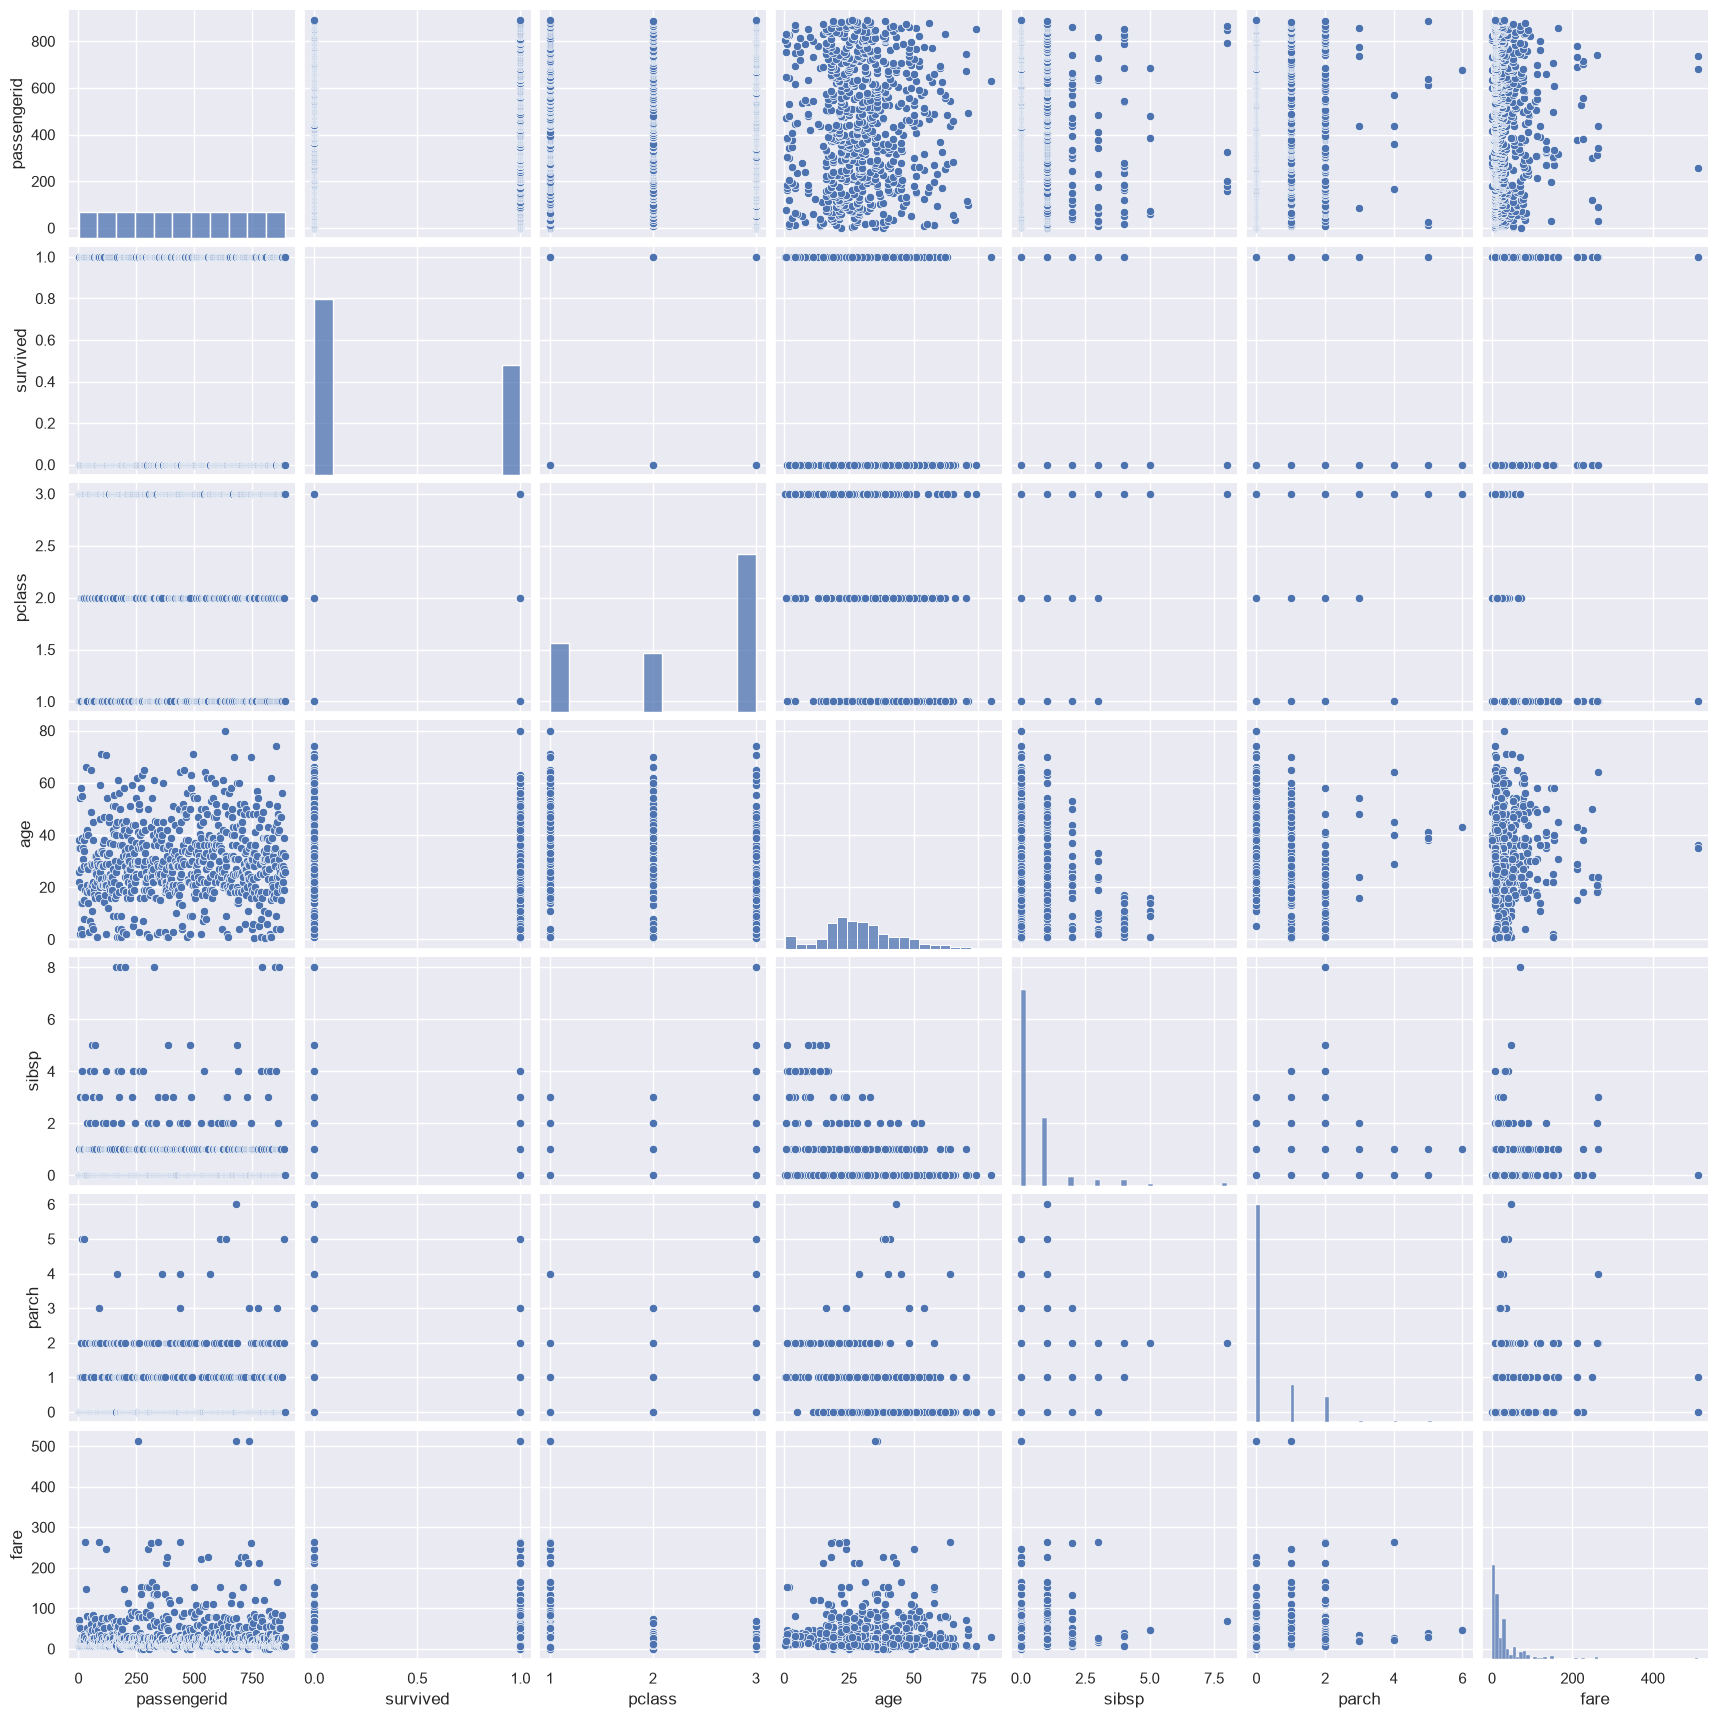

In [80]:
# 2. Visualize all the data using sns.pairplot.
sns.pairplot(df)
plt.show()

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [81]:
# 3. Check for null values.
df.info()
df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   name         891 non-null    str    
 4   sex          891 non-null    str    
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    str    
 9   fare         891 non-null    float64
 10  cabin        204 non-null    str    
 11  embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

## #2 Select and Engineer Features

1. Fill age null values with -999.
2. Convert to numerical values if needed be by using `pd.get_dummies()`.
3. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
4. Define our `X` and `y`.
5. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Fill age null values with -999.</span></p>
</div>


In [82]:
# 1. Fill age null values with -999.
df['ages'] = df['age'].fillna(-999)


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Convert to numerical values if needed be by using `pd.get_dummies()`.</span></p>
</div>


In [83]:
# 2. Convert to numerical values if needed be by using `pd.get_dummies()`.
df['sex'] = pd.get_dummies(df['sex'], drop_first=True) # TRUE = is male


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.</span></p>
</div>


In [84]:
# Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.
df.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,ages
0,1,0,3,"Braund, Mr. Owen Harris",True,22.0,1,0,A/5 21171,7.2500,NaN,S,22.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",False,38.0,1,0,PC 17599,71.2833,C85,C,38.0
2,3,1,3,"Heikkinen, Miss. Laina",False,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,26.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",False,35.0,1,0,113803,53.1000,C123,S,35.0
4,5,0,3,"Allen, Mr. William Henry",True,35.0,0,0,373450,8.0500,NaN,S,35.0


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Create a list of the features we are going to use.</span></p>
</div>


In [85]:
# 3. Create a list of the features we are going to use.
features = ['age', 'sex', 'fare']


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Define our `X` and `y`. The target column for `y` is `survived`.</span></p>
</div>


In [86]:
# 4. Define our `X` and `y`.
x = df[features]
y = df['survived']


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Split our data into trainig and testing sets.</span></p>
</div>


In [87]:
# 5. Split our data into trainig and testing sets.

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## #3 Build and Train Model

1. For our first pass, initialize our model with `max_depth=2`.
2. Fit our model with our training data. 
3. Make predictions of our testing data.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. For our first pass, initialize our model with `max_depth=2`.</span></p>
</div>


In [88]:
# 1. For our first pass, initialize our model with `max_depth=2`.
model = DecisionTreeClassifier(max_depth=2)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Fit our model with our training data.</span></p>
</div>


In [89]:
# 2. Fit our model with our training data. 
model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Make predictions of our testing data.</span></p>
</div>


In [90]:
# 3. Make predictions of our testing data. 
y_pred = model.predict(x_test)


## #4 Evaluate Model

1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores. 
    * To calculate auc score you have to get the predicted probabilites for the Survived class using `model.predict_proba(X_test)[:,1]`
2. Visualize our Decision Tree using provided code.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.<br>Calculate predicted probabilities.<br>Keep only the probabilities for True.<br>Compute auc score.</span></p>
</div>


In [91]:
# 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.
print("Accuracy:", "\t", accuracy_score(y_pred, y_test,))
print("Precision:", "\t", precision_score(y_pred, y_test))
print("Recall:", "\t", recall_score(y_pred, y_test))
print("F1 Score:", "\t", f1_score(y_pred, y_test))


# Calculate predicted probabilities.
y_pred_proba = model.predict_proba(x_test)

# Keep only the probabilities for True.
y_pred_proba_true = y_pred_proba[:, 1]

# Compute auc score.
print("AUC Score True only:", "\t", roc_auc_score(y_test, y_pred_proba_true))


Accuracy: 	 0.7821229050279329
Precision: 	 0.7162162162162162
Recall: 	 0.7464788732394366
F1 Score: 	 0.7310344827586207
AUC Score True only: 	 0.7945945945945945


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


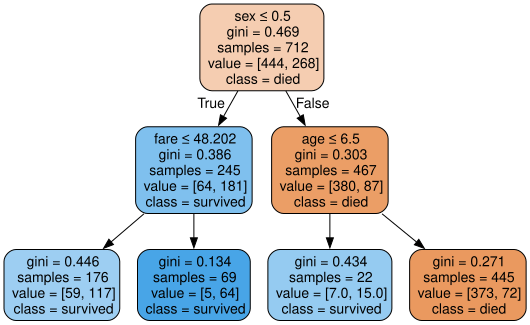

In [92]:
# 2. Visualize your decision tree.

dot_data = tree.export_graphviz(model, out_file=None, 
                     feature_names=features,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)  
graph = graphviz.Source(dot_data)
graph


## Picking the right parameters...

## Parameter tuning of your Decision Tree using GridSearch

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Visualize your best tree.
7. Which feature was your most important feature?

```python
tree.DecisionTreeClassifier(
    *,
    criterion='gini',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=None,
    random_state=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    class_weight=None,
    presort='deprecated',
    ccp_alpha=0.0,
)
```


[Tips on how to customize / set the paramters in the decision tree.](https://scikit-learn.org/stable/modules/tree.html#tips-on-practical-use)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [93]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.
parameters = {
    "max_depth":[3, 5, 7],
    "min_samples_split":[2, 5, 10],
    "min_samples_leaf":[1, 2, 4]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [94]:
# 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.

grid_search = GridSearchCV(DecisionTreeClassifier(), parameters, scoring='precision')

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [95]:
# 3. Fit your GridSearchCV with your training data. 

grid_search.fit(x_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [96]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print("Best parameters: ", grid_search.best_params_)


Best parameters:  {'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 2}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [97]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you the best Tree.
best_model = grid_search.best_estimator_
# Now lets evaluate our model.
y_pred = best_model.predict(x_test)
# Calculate predicted probabilities, keep only probability for when class = 1.
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

y_pred_proba = best_model.predict_proba(x_test)[:, 1]
print("AUC Score:", roc_auc_score(y_test, y_pred_proba))

Accuracy: 0.776536312849162
Precision: 0.8035714285714286
Recall: 0.6081081081081081
F1 Score: 0.6923076923076923
AUC Score: 0.7953024453024453


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


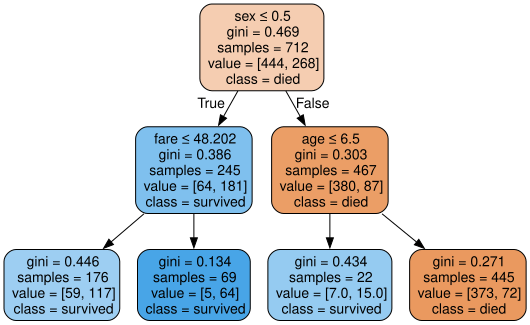

In [98]:
# 6. Visualize your best tree.

dot_data = tree.export_graphviz(model, out_file=None, 
                     feature_names=features,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)  
graph = graphviz.Source(dot_data)
graph


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 7. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [99]:
# 7. Which feature was your most important feature?
#    Now lets look at our feature importances.


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
# Sex was the most important feature

<p style="text-align:center;">Write your answer in this cell after the table above.</p>


## Now onto Random Forests...
### We are going to do the same, but this time with a Random Forest. Remeber... Repetition is the father of learning.

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Which feature was your most important feature?


## Parameters of the Random Forest Classifier

```python
RandomForestClassifier(
    n_estimators=100,
    *,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features='auto',
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    bootstrap=True,
    oob_score=False,
    n_jobs=None,
    random_state=None,
    verbose=0,
    warm_start=False,
    class_weight=None,
    ccp_alpha=0.0,
    max_samples=None,
)
```

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [100]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
parameters = {
    "max_depth": [2,4,8],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,5]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [101]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
grid_search = GridSearchCV(RandomForestClassifier(), parameters, scoring='accuracy')



<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [102]:
# 3. Fit your GridSearchCV with your training data.
grid_search.fit(x_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [103]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print("Best parameters: ", grid_search.best_params_)

Best parameters:  {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [104]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you tree that has the highest f1-score.
f_score = GridSearchCV(RandomForestClassifier(), parameters, scoring='f1')

f_score.fit(x_train, y_train)

best_f_score = f_score.best_estimator_
print("Best model with highest F1 score:", best_f_score)

# Now lets evaluate our model.
best_f_score_pred = best_f_score.predict(x_test)
# Calculate predicted probabilities, keep only probability for when class = 1.
print("Accuracy:", accuracy_score(y_test, best_f_score_pred))
print("Precision:", precision_score(y_test, best_f_score_pred))
print("Recall:", recall_score(y_test, best_f_score_pred))
print("F1 Score:", f1_score(y_test, best_f_score_pred))

y_pred_proba = best_f_score.predict_proba(x_test)[:, 1]
print("AUC Score:", roc_auc_score(y_test, y_pred_proba))

Best model with highest F1 score: RandomForestClassifier(max_depth=8, min_samples_leaf=2)
Accuracy: 0.8100558659217877
Precision: 0.8125
Recall: 0.7027027027027027
F1 Score: 0.7536231884057971
AUC Score: 0.8697554697554697


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 6. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [105]:
# 6. Which feature was your most important feature?
#    Now lets look at our feature importances.
important_feature = best_f_score.feature_importances_
important_feature_names = best_f_score.feature_names_in_

importance = dict(zip(important_feature_names, important_feature))

for feature, importance_value in importance.items():
    print("feature:", feature, "importance:", importance_value)


feature: age importance: 0.2488024914487792
feature: sex importance: 0.41610209421913674
feature: fare importance: 0.33509541433208406


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
feature sex was most important (0.50)
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


## Build a Random Forest using the ny-vs-sf-houses.csv data.

* Your target variable, aka the column you are trying to predict, aka your `y` variable is `in_sf`. 
* Can you get an accuracy above 88.8889%?
* What was your most important feature?


***
<h1 align="center"> <span style="color:#FF0000"> BUILD, TRAIN, AND EVAULATE A RANDOM FOREST MODEL BELOW. </span> </h1>

***


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>
    
1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load ny-vs-sf-houses data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the ny-vs-sf-houses data set.<br>Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.</span></p>
</div>


In [106]:
# 1. Load in the ny-vs-sf-houses data set.
#    Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.
df = pd.read_csv("data/ny-vs-sf-houses.csv")
# Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.
df.head()


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


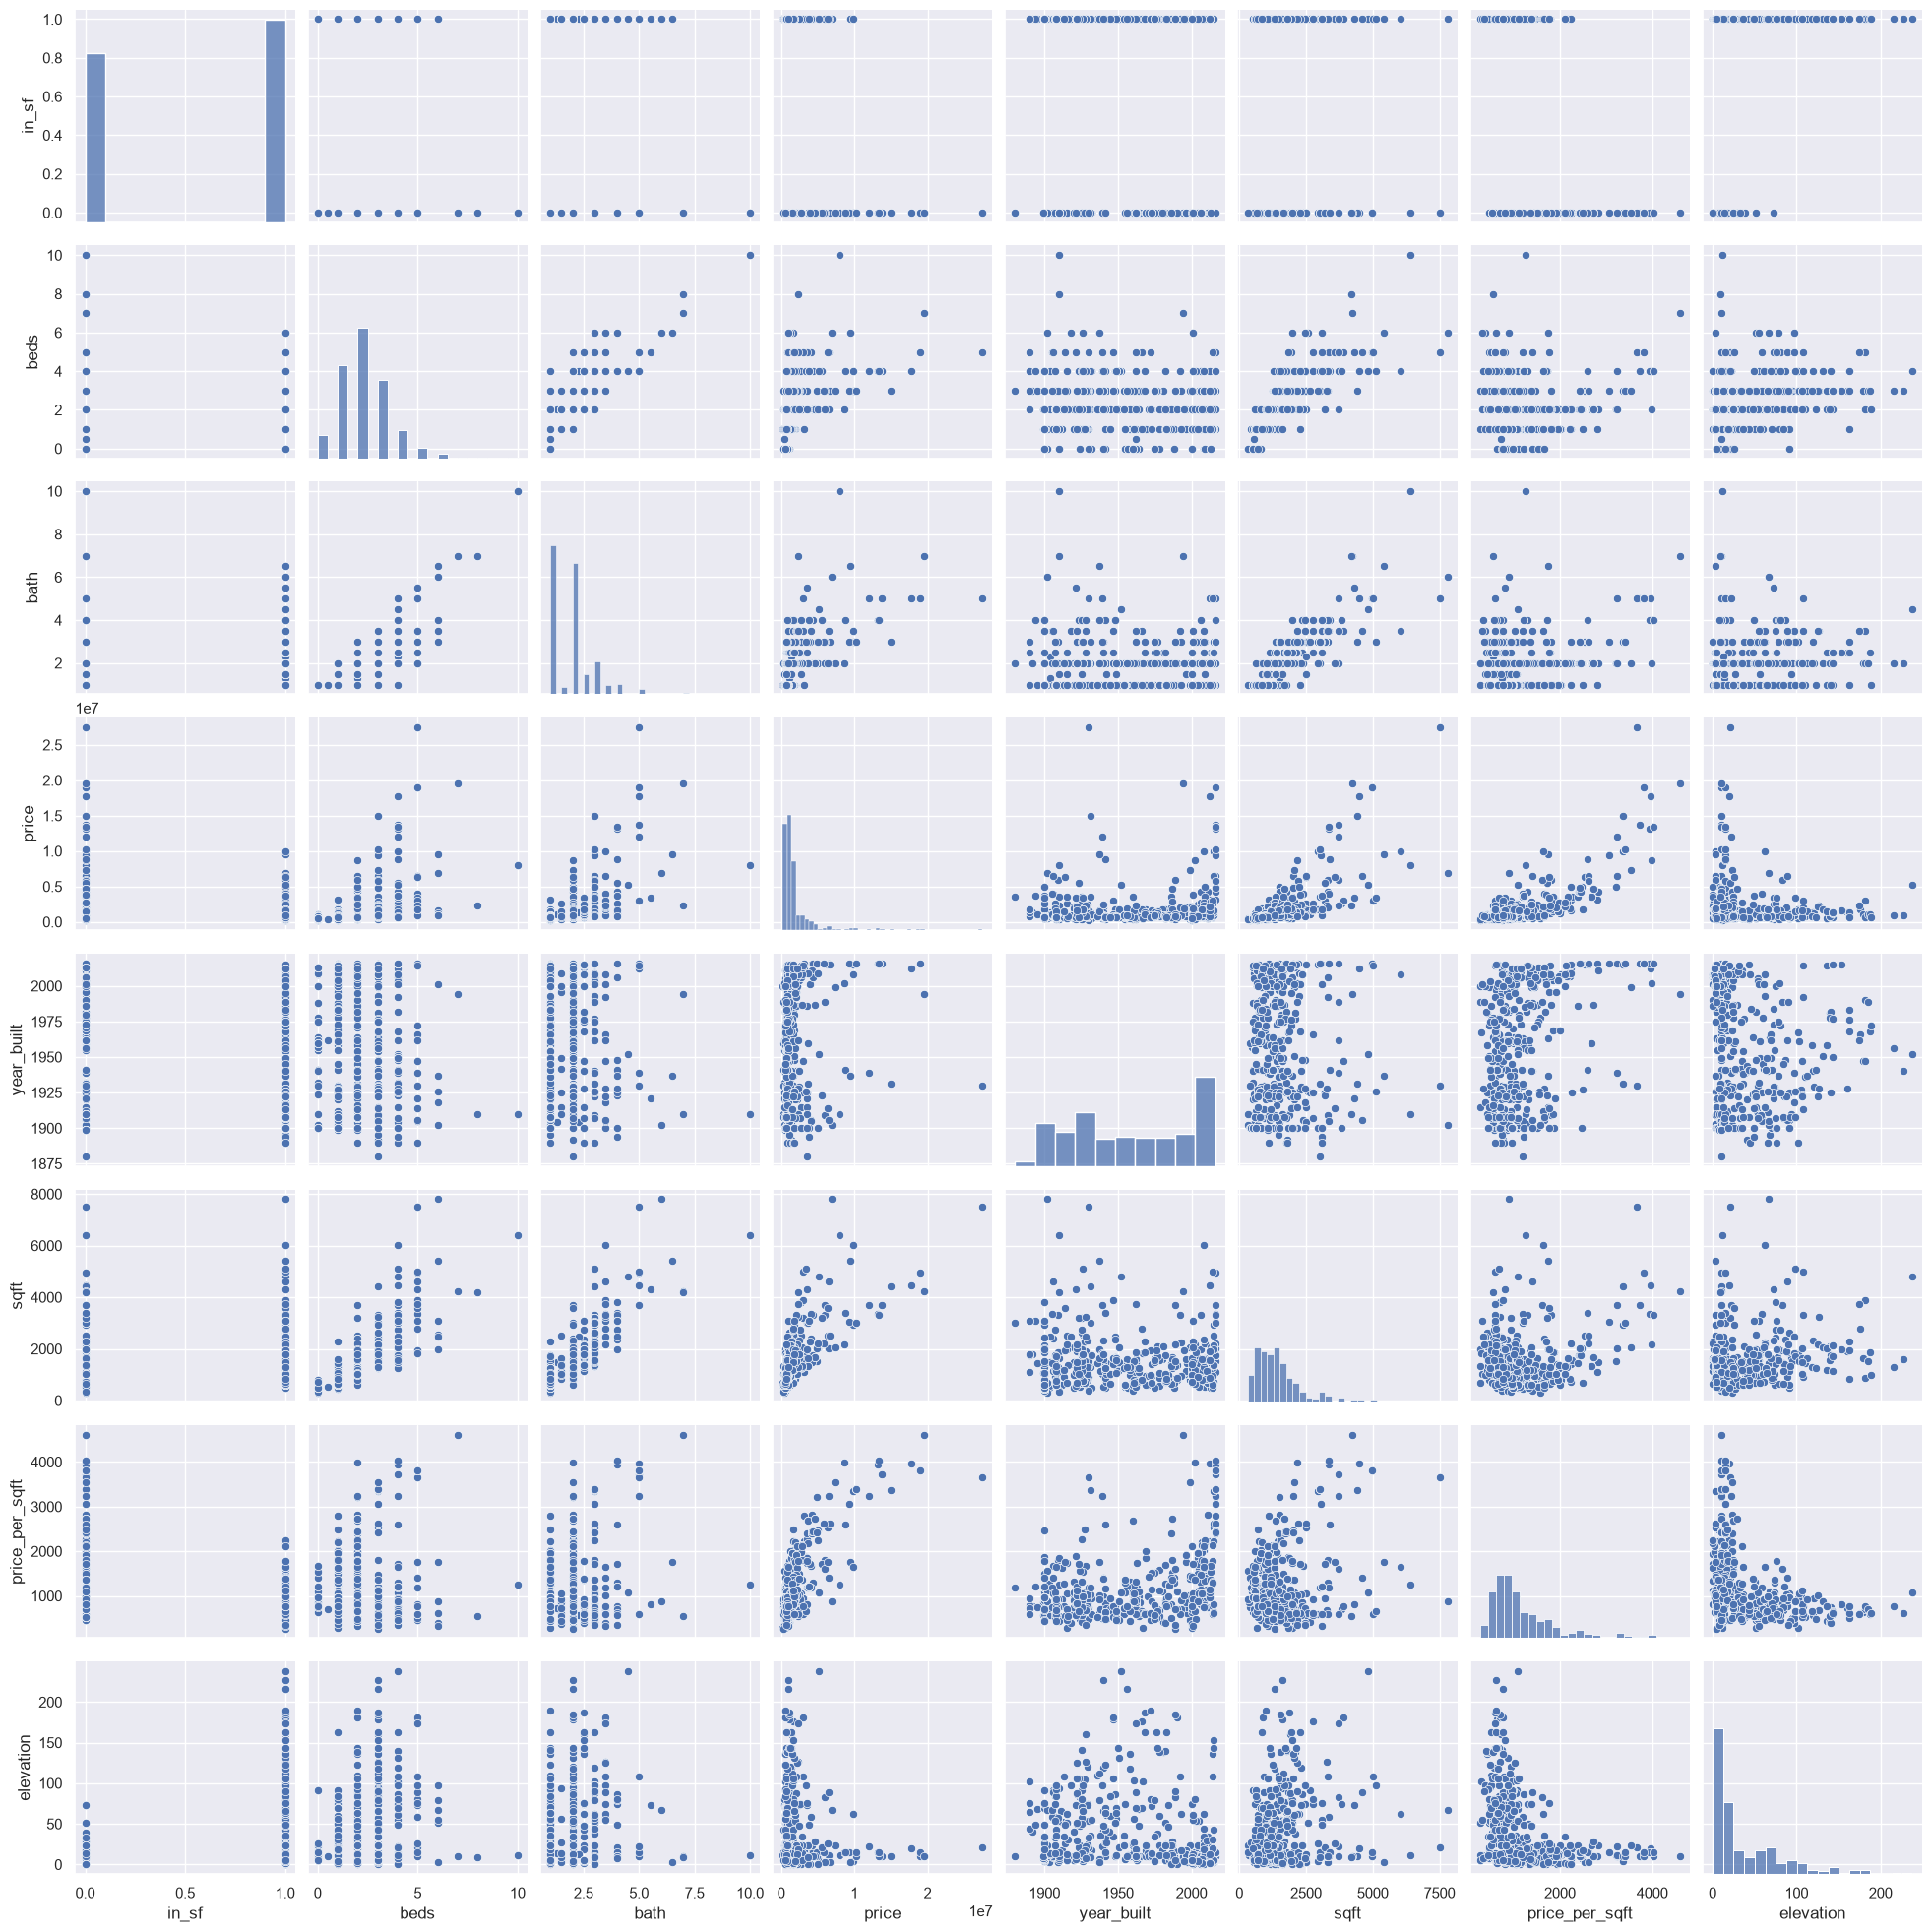

In [107]:
# 2. Visualize all the data using sns.pairplot.
sns.pairplot(df)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> Visualize all the data using sns.pairplot.</span></p>
</div>


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [108]:
# 3. Check for null values.
print( df.isnull().sum())
print( df.info())
print(df.value_counts())

in_sf             0
beds              0
bath              0
price             0
year_built        0
sqft              0
price_per_sqft    0
elevation         0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 492 entries, 0 to 491
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   in_sf           492 non-null    int64  
 1   beds            492 non-null    float64
 2   bath            492 non-null    float64
 3   price           492 non-null    int64  
 4   year_built      492 non-null    int64  
 5   sqft            492 non-null    int64  
 6   price_per_sqft  492 non-null    int64  
 7   elevation       492 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 30.9 KB
None
in_sf  beds  bath  price    year_built  sqft  price_per_sqft  elevation
0      0.0   1.0   439000   1930        500   878             10           2
       1.0   1.0   999000   1982        784   1274            5            2
  

## #2 Select and Engineer Features

1. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
2. Define our `X` and `y`.
3. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Create a list of the features you are going to use.<br>2. Define our `X` and `y`.<br>3. Split our data into trainig and testing sets.</span></p>
</div>


In [109]:
# 1. Create a list of the features you are going to use.
features = ['price_per_sqft', 'year_built', 'beds','elevation']

# 2. Define our `X` and `y`.
x = df[features]
y = df['in_sf']

# 3. Split our data into trainig and testing sets.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)



## #3 Build and Train Model

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [117]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
param_grid = {
    "n_estimators":[300,400,500],
    "max_depth":[3,5,None],
    "min_samples_split":[2,5,10]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [118]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
grid_search = GridSearchCV(RandomForestClassifier(), param_grid, scoring='accuracy')



<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [119]:
# 3. Fit your GridSearchCV with your training data.
grid_search.fit(x_train,y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [300, 400, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [120]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print(grid_search.best_params_)


{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}


## #4 Evaluate Model

1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
2. Which feature was your most important feature?


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [121]:
# 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you tree that has the highest f1-score.
best_model = grid_search.best_estimator_

# Now lets evaluate our model.
y_pred = best_model.predict(x_test)
# Calculate predicted probabilities, keep only probability for when class = 1.
y_pred_proba = best_model.predict_proba(x_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("AUC Score:", roc_auc_score(y_test, y_pred_proba))


Accuracy: 0.9191919191919192
Precision: 0.9285714285714286
Recall: 0.9285714285714286
F1 Score: 0.9285714285714286
AUC Score: 0.9727990033222591


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [122]:
# 2. Which feature was your most important feature?
#    Now lets look at our feature importances.
important_feature = best_model.feature_importances_
important_feature_names = best_model.feature_names_in_

importance = dict(zip(important_feature_names, important_feature))

for feature, importance_value in importance.items():
    print("feature:", feature, "importance:", importance_value)

feature: price_per_sqft importance: 0.3270258998531099
feature: year_built importance: 0.16630717885067042
feature: beds importance: 0.07741123594601076
feature: elevation importance: 0.4292556853502087


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
Elevation is the most important feature. (0.43)
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


# Awesome difficult extra credit below:
Build a classifier using the adult_income.csv data.  
* The target variable is 'class'.
* Start with just using these features `selected_features = ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']`
* You have to include the pos_label in your precision, recall, and f1 scores. It just tells the classifier which one is the posotive label.  I provided the proper way below.

* See if you can get above 50% f1 score.  
* See some [super tricks and tips here](https://www.kaggle.com/code/jieyima/income-classification-model)